<a href="https://colab.research.google.com/github/naabiiill/Machine_Learning/blob/main/M_15_Image_Classification_with_Deep_Learning_and_CNNs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


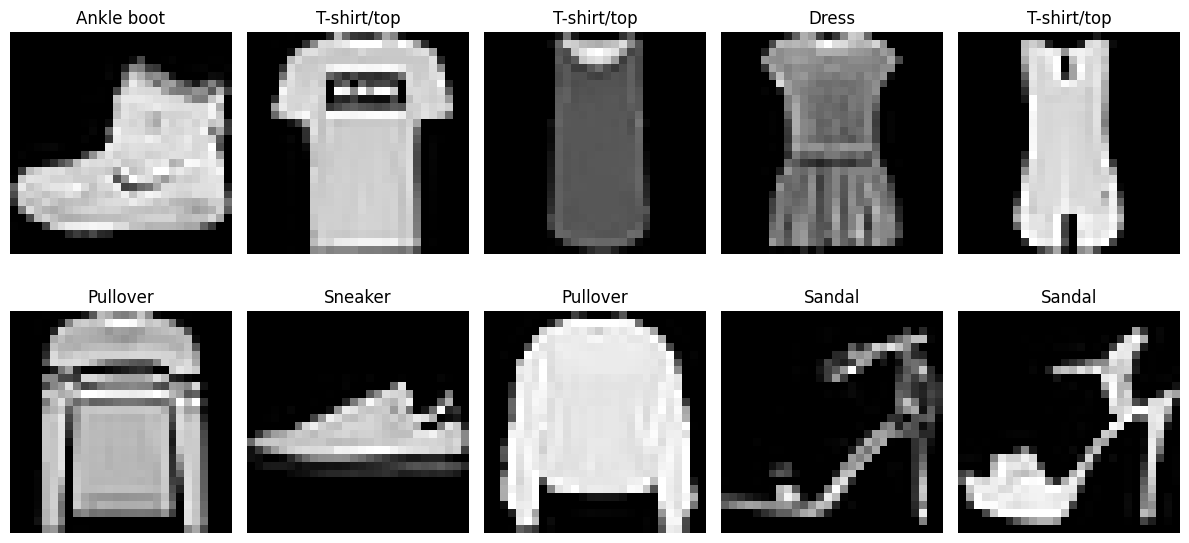

In [2]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("Pixel value range:", X_train.min(), "to", X_train.max())

Training samples: 48000
Validation samples: 12000
Test samples: 10000
Pixel value range: 0.0 to 1.0


In [4]:
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
history_baseline = baseline_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8177 - loss: 0.5111 - val_accuracy: 0.8668 - val_loss: 0.3738
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8633 - loss: 0.3728 - val_accuracy: 0.8710 - val_loss: 0.3550
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8763 - loss: 0.3345 - val_accuracy: 0.8789 - val_loss: 0.3363
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8849 - loss: 0.3086 - val_accuracy: 0.8842 - val_loss: 0.3246
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8924 - loss: 0.2905 - val_accuracy: 0.8873 - val_loss: 0.3262
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8979 - loss: 0.2746 - val_accuracy: 0.8821 - val_loss: 0.3252
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9026 - loss: 0.2594 - val_accuracy: 0.8871 - val_loss: 0.3142
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9051 - loss: 0.2503 - val_accuracy: 0.

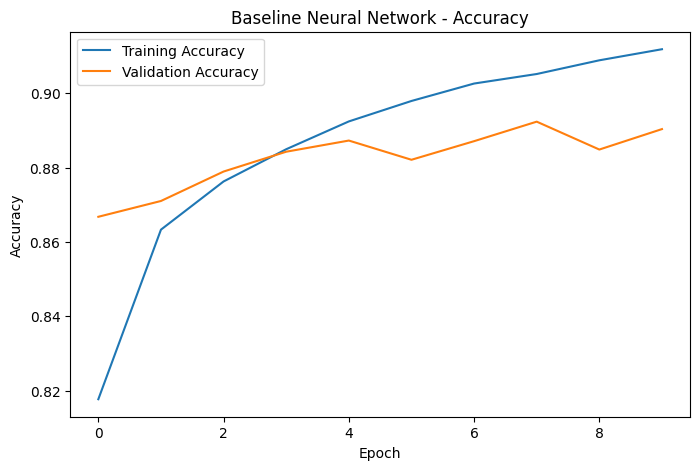

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["accuracy"], label="Training Accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline Neural Network - Accuracy")
plt.legend()
plt.show()

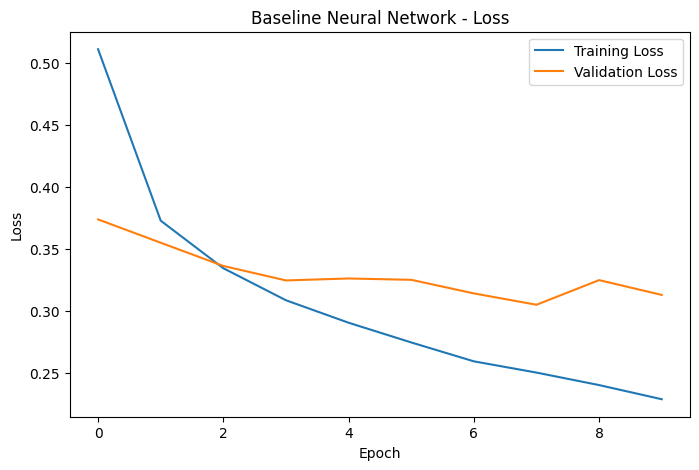

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["loss"], label="Training Loss")
plt.plot(history_baseline.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Neural Network - Loss")
plt.legend()
plt.show()

In [9]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896,906 (3.42 MB)

 Trainable params: 896,906 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("CNN training shape:", X_train_cnn.shape)

CNN training shape: (48000, 28, 28, 1)


In [11]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 92s 121ms/step - accuracy: 0.8091 - loss: 0.5364 - val_accuracy: 0.8743 - val_loss: 0.3486
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 134s 110ms/step - accuracy: 0.8820 - loss: 0.3323 - val_accuracy: 0.8983 - val_loss: 0.2752
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 143s 111ms/step - accuracy: 0.8997 - loss: 0.2798 - val_accuracy: 0.9128 - val_loss: 0.2374
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 112ms/step - accuracy: 0.9088 - loss: 0.2523 - val_accuracy: 0.9179 - val_loss: 0.2237
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 142s 111ms/step - accuracy: 0.9181 - loss: 0.2253 - val_accuracy: 0.9227 - val_loss: 0.2162
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 89s 118ms/step - accuracy: 0.9260 - loss: 0.2048 - val_accuracy: 0.9235 - val_loss: 0.2136
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 111ms/step - accuracy: 0.9323 - loss: 0.1853 - val_accuracy: 0.9260 - val_loss: 0.2105
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 110ms/step - accuracy: 0.9389 - loss

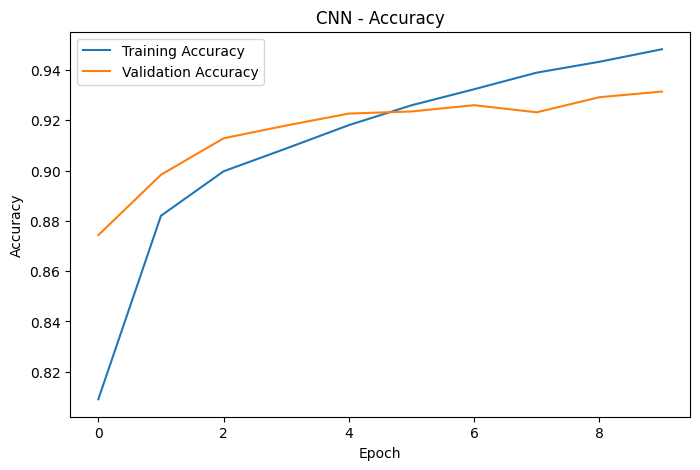

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN - Accuracy")
plt.legend()
plt.show()

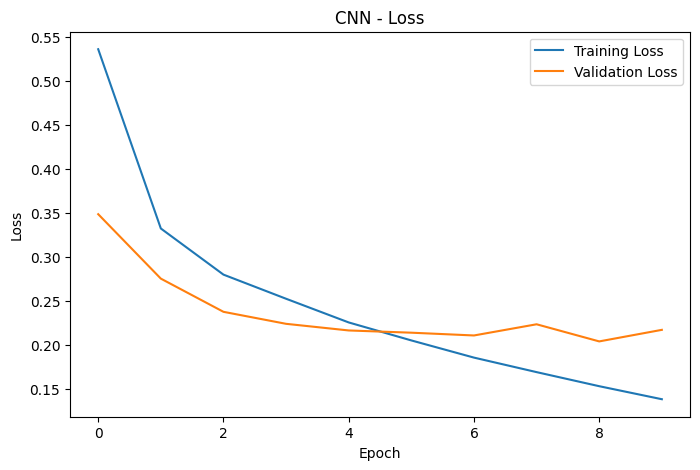

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN - Loss")
plt.legend()
plt.show()

In [15]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test, y_test, verbose=0
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test_cnn, y_test, verbose=0
)

print("Baseline Test Accuracy:", round(baseline_accuracy, 4))
print("CNN Test Accuracy:", round(cnn_accuracy, 4))

Baseline Test Accuracy: 0.8821
CNN Test Accuracy: 0.9226


In [16]:
comparison = pd.DataFrame({
    "Model": ["Baseline Neural Network", "CNN"],
    "Trainable Parameters": [
        baseline_model.count_params(),
        cnn_model.count_params()
    ],
    "Test Accuracy": [
        baseline_accuracy,
        cnn_accuracy
    ]
})

print(comparison.to_string(index=False))

                  Model  Trainable Parameters  Test Accuracy
Baseline Neural Network                235146         0.8821
                    CNN                896906         0.9226


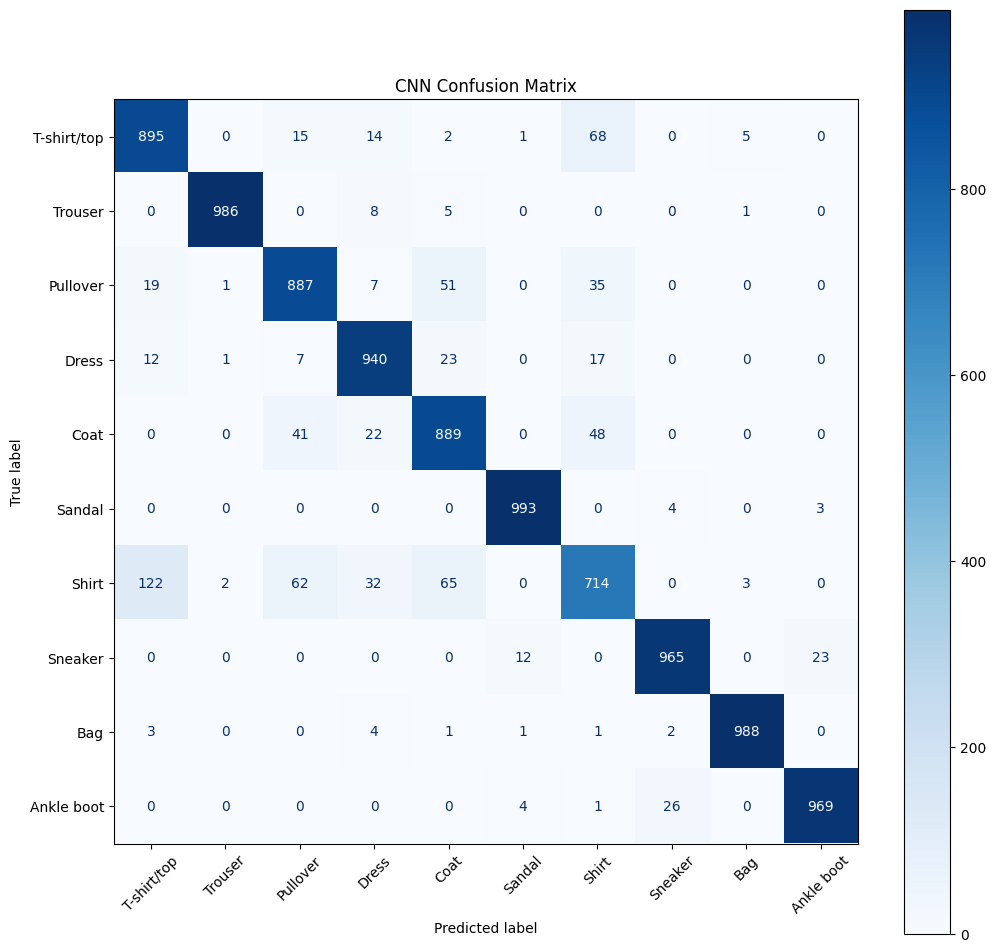

In [17]:
y_pred_prob = cnn_model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 12))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.show()

Total misclassified images: 774


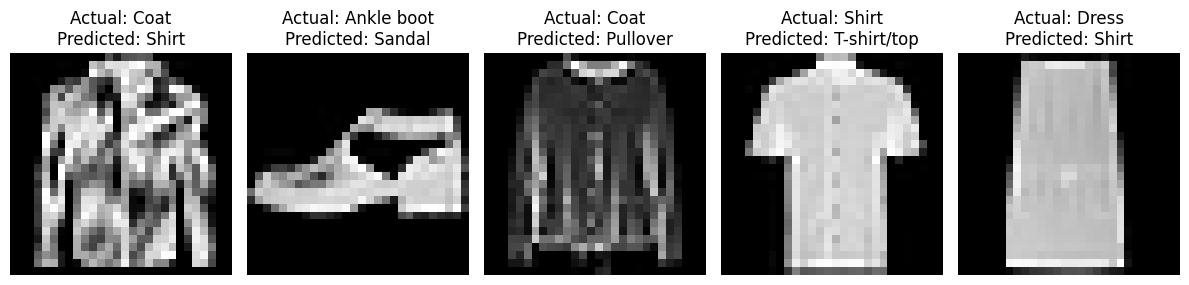

In [18]:
incorrect_indices = np.where(y_pred != y_test)[0]

print("Total misclassified images:", len(incorrect_indices))

plt.figure(figsize=(12, 6))

for i, index in enumerate(incorrect_indices[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"Actual: {class_names[y_test[index]]}\n"
        f"Predicted: {class_names[y_pred[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
for index in incorrect_indices[:5]:
    print("Actual:", class_names[y_test[index]])
    print("Predicted:", class_names[y_pred[index]])
    print()

Actual: Coat
Predicted: Shirt

Actual: Ankle boot
Predicted: Sandal

Actual: Coat
Predicted: Pullover

Actual: Shirt
Predicted: T-shirt/top

Actual: Dress
Predicted: Shirt



Some clothing items have similar shapes and appearances, making them difficult to distinguish.



The images are small and grayscale, so some details and textures are missing.



Different clothing items may have similar outlines, such as shirts, coats, and pullovers.



Some images may have unusual shapes or poses that make classification harder.



The model learns patterns from the training data, but it may not correctly identify every ambiguous image

## Reflection

In this assignment, I built two deep learning models to classify images from the Fashion-MNIST dataset. The first model was a fully-connected neural network, while the second model was a Convolutional Neural Network (CNN). Both models were trained using the same training and validation data, and their performance was evaluated using the test dataset.

The CNN is expected to outperform the fully-connected neural network because it is specifically designed for image data. The fully-connected network flattens each image into a one-dimensional array, which removes the direct spatial arrangement of the pixels. As a result, it may find it difficult to learn local patterns such as edges, shapes, and textures. In contrast, a CNN uses convolutional filters to detect local features and combines these features to recognize more complex patterns. Its filters are shared across different image locations, which allows it to learn useful features with fewer parameters than a comparable dense architecture. However, the actual parameter counts and test accuracies depend on the models used.

Overfitting can be observed by comparing training and validation performance. If training accuracy continues to increase while validation accuracy stops improving or decreases, the model may be overfitting the training data. Similarly, a decreasing training loss combined with an increasing validation loss can indicate overfitting. The CNN includes a Dropout layer to reduce this problem by randomly disabling some neurons during training. The training and validation curves help show whether this technique was effective.

The confusion matrix provides additional information about the CNN's performance for each clothing category. It shows which classes were correctly predicted and which classes were confused with one another. Some items, such as shirts, coats, and pullovers, can have similar shapes and appearances. Because the images are small and grayscale, important visual details may be difficult to recognize. These similarities can explain some of the misclassified images.

To improve accuracy in the future, I would experiment with additional convolutional layers, different filter sizes, and alternative learning rates. I would also try Batch Normalization, data augmentation, and early stopping. Finally, I would compare different architectures and training settings using validation performance before evaluating the final model on the test set.

Overall, this assignment helped me understand the difference between fully-connected networks and CNNs and why convolutional layers are useful for image classification.